In [1]:
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
from ipywidgets import interactive, FloatSlider, IntSlider, Layout 
import plotly.graph_objects as go
import pyvista as pv

JPEG (3605, 3604) RGB


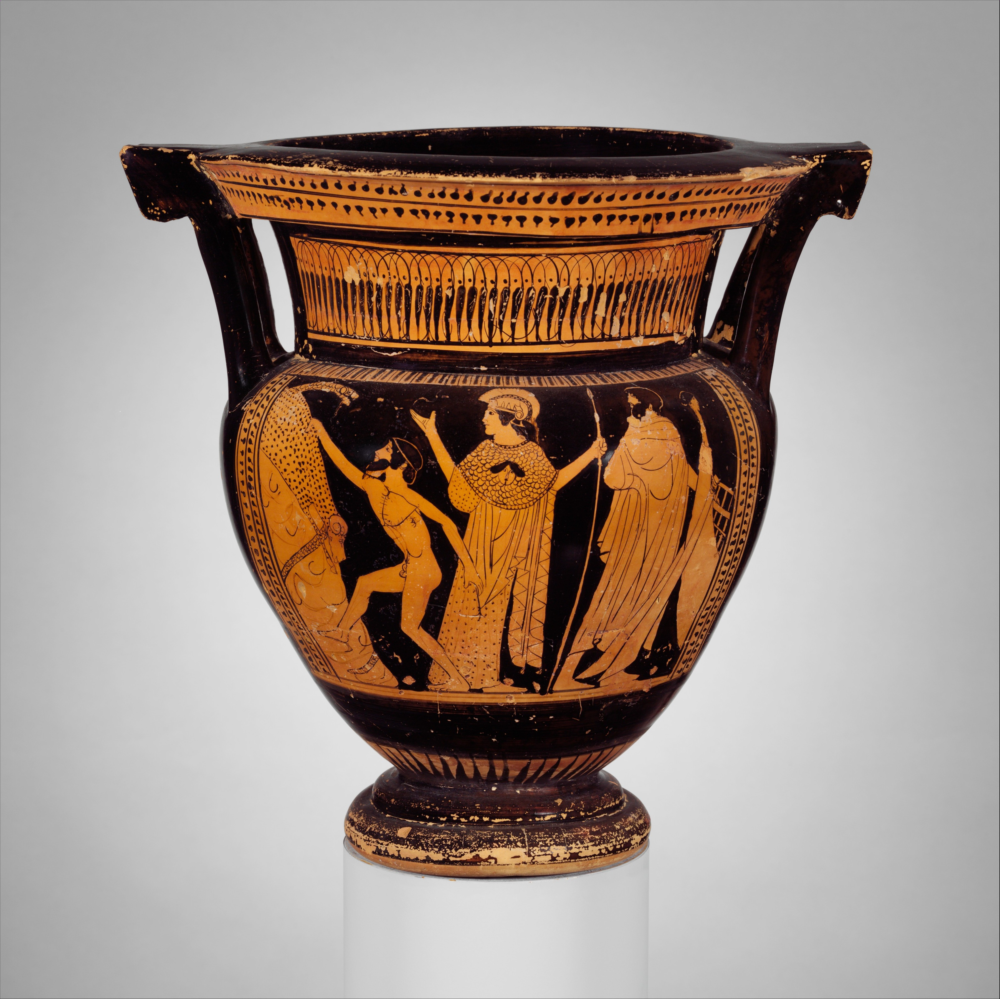

In [2]:
with Image.open('samples/DP153296.jpg') as test_img:
    test_img.load()
    print(test_img.format, test_img.size, test_img.mode) 
display(test_img)

-------
# Simple transform

In [3]:
test_img = plt.imread('samples/DP153296.jpg')
print(test_img.shape, test_img.dtype)

(3604, 3605, 3) uint8


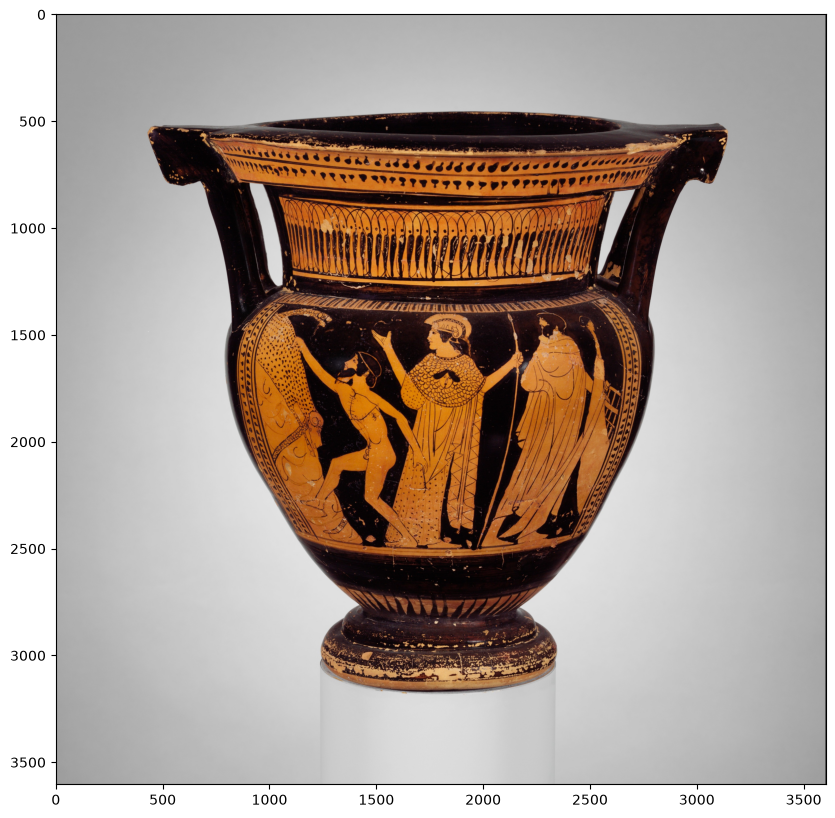

In [4]:
fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(test_img)

since it's on its side, the formula for the profile function is 

`r(y) = r₀ + a·(y − y₀)² + b·(y − y₀)³`

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interactive, FloatSlider, IntSlider, IntRangeSlider, Layout

img = plt.imread('samples/DP153296.jpg')
h, w = img.shape[:2]
small = img[::4, ::4]   # every 4th pixel, for faster redraws

def radius(y, y0, r0, A_up, A_down, C_up, C_down):
    t = (y - y0) / 1000                    # distance from the bulge, in units of 1000 px
    above = t < 0                          # rows count downward, so above the bulge is t < 0
    A = np.where(above, A_up, A_down)
    C = np.where(above, C_up, C_down)
    return r0 + A * t**2 + C * t**4

def inflection_row(y0, A, C, side):
    """Row where the profile's bend changes direction, or None if it doesn't."""
    if A * C >= 0:
        return None
    t = np.sqrt(-A / (6 * C))
    return y0 - 1000 * t if side == 'up' else y0 + 1000 * t

def draw(cx, y0, r0, A_up, A_down, C_up, C_down, rows):
    y_top, y_bottom = rows
    y = np.linspace(y_top, y_bottom, 1000)
    r = radius(y, y0, r0, A_up, A_down, C_up, C_down)

    fig, ax = plt.subplots(figsize=(9, 9))
    ax.imshow(small, extent=(0, w, h, 0))   # keep full-resolution pixel coordinates
    ax.plot(cx + r, y, color='yellow', lw=1.5)
    ax.plot(cx - r, y, color='yellow', lw=1.5)
    ax.axvline(cx, color='cyan', ls='--', lw=1)
    ax.axhline(y0, color='magenta', ls=':', lw=1)
    for yl in rows:
        ax.axhline(yl, color='white', ls=':', lw=0.8)

    for A, C, side in ((A_up, C_up, 'up'), (A_down, C_down, 'down')):
        yi = inflection_row(y0, A, C, side)
        if yi is not None:
            ri = radius(yi, y0, r0, A_up, A_down, C_up, C_down)
            ax.plot([cx - ri, cx + ri], [yi, yi], 'o', color='red', ms=6)

    ax.set_xlim(0, w)
    ax.set_ylim(h, 0)   # y increases downward, like the image
    plt.show()

style = {'description_width': 'initial'}
wide = Layout(width='600px')

def slider(value, lo, hi, text):
    return FloatSlider(value=value, min=lo, max=hi, step=1, continuous_update=False,
                       style=style, layout=wide, description=text)

fit = interactive(
    draw,
    cx=IntSlider(value=1796, min=1500, max=2100, style=style, layout=wide,
                 description='cx: axis column (px)'),
    y0=IntSlider(value=1600, min=0, max=h, style=style, layout=wide,
                 description='y0: row of widest point (px)'),
    r0=IntSlider(value=961, min=500, max=1400, style=style, layout=wide,
                 description='r0: radius at widest point (px)'),
    A_up=slider(-2076, -5000, 0, 'A_up: taper above the bulge'),
    A_down=slider(-402, -5000, 0, 'A_down: taper below the bulge'),
    C_up=slider(0, -5000, 20000, 'C_up: flatness above (+ = inflection, bigger = closer)'),
    C_down=slider(0, -5000, 20000, 'C_down: flatness below (+ = inflection, bigger = closer)'),
    rows=IntRangeSlider(value=(1289, 2439), min=0, max=h, step=1,
                        continuous_update=False, style=style, layout=wide,
                        description='rows: top and bottom of the curve (px)'),
)

for widget in fit.children[:-1]:  # last child is the plot output
    widget.description = widget.description.split(":", 1)[0]
    widget.style.description_width = "75px"
    widget.layout.width = "700px"
    
display(fit)

interactive(children=(IntSlider(value=1796, description='cx', layout=Layout(width='700px'), max=2100, min=1500…

In [6]:
params = fit.kwargs
y_top, y_bottom = params['rows']
shape = {k: params[k] for k in ('y0', 'r0', 'A_up', 'A_down', 'C_up', 'C_down')}
r = radius(np.arange(y_top, y_bottom), **shape)

print(params)

{'cx': 1796, 'y0': 1600, 'r0': 961, 'A_up': -2076.0, 'A_down': -402.0, 'C_up': 0.0, 'C_down': 0.0, 'rows': (1289, 2439)}


# curve fit, visualize in 3d

In [10]:
fig = go.Figure(go.Surface(x=X, y=Z, z=H, surfacecolor=H, colorscale='Oranges', showscale=False))
fig.update_layout(scene=dict(aspectmode='data'), width=800, height=800)   # 'data' = true proportions
fig.show()

In [20]:

pv.set_jupyter_backend('trame')

cx = params['cx']

# front half: textured from the photo
theta = np.linspace(-np.pi / 2, np.pi / 2, 180)
rows = np.arange(y_top, y_bottom, 10, dtype=float)
T, Y = np.meshgrid(theta, rows)
R = radius(Y, **shape)
X, Z, H = R * np.sin(T), R * np.cos(T), -Y

front = pv.StructuredGrid(X, Z, H)
tex_u = (cx - X) / w
# tex_u = (cx + R * np.sin(T)) / w      # photo column, scaled to 0-1
tex_v = 1 - Y / h                     # photo row, scaled to 0-1 (textures count up from the bottom)
front.active_texture_coordinates = np.c_[tex_u.ravel(order='F'), tex_v.ravel(order='F')]

# back half: never seen by the camera, so plain gray
theta_b = np.linspace(np.pi / 2, 3 * np.pi / 2, 90)
Tb, Yb = np.meshgrid(theta_b, rows)
Rb = radius(Yb, **shape)
back = pv.StructuredGrid(Rb * np.sin(Tb), Rb * np.cos(Tb), -Yb)

pl = pv.Plotter()
pl.add_mesh(front, texture=pv.read_texture('samples/DP153296.jpg'))
pl.add_mesh(back, color='gray')
pl.show()

Widget(value='<iframe src="http://localhost:56733/index.html?ui=P_0x1320911d0_5&reconnect=auto" class="pyvista…

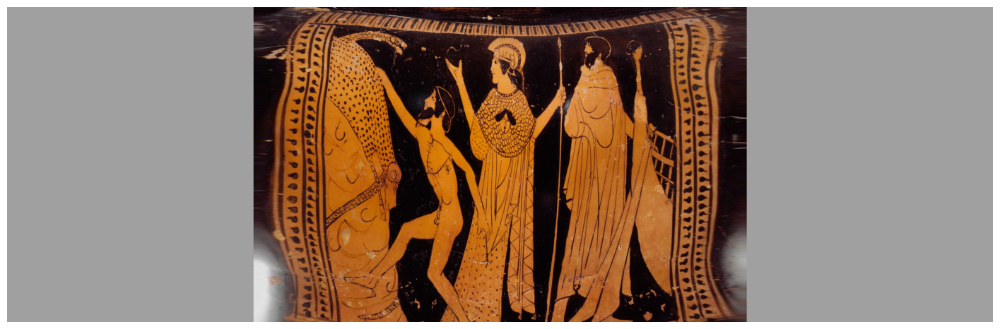

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import map_coordinates

# Use your existing `params`, or uncomment this example:
# params = {
#     "cx": 1796, "y0": 1600, "r0": 961,
#     "A_up": -2076.0, "A_down": -402.0,
#     "C_up": 0.0, "C_down": 0.0,
#     "rows": (1289, 2439),
# }

def radius(y, y0, r0, A_up, A_down, C_up, C_down):
    t = (y - y0) / 1000
    A = np.where(t < 0, A_up, A_down)
    C = np.where(t < 0, C_up, C_down)
    return r0 + A * t**2 + C * t**4


def unwrap_photo(
    image_path,
    params,
    output_path="unwrapped.png",
    width=3600,
    front_only=False,
):
    image = np.asarray(Image.open(image_path).convert("RGB"))
    image_h, image_w = image.shape[:2]

    y_top, y_bottom = params["rows"]
    if not (0 <= y_top < y_bottom < image_h):
        raise ValueError("params['rows'] must be within the image.")

    # One output row per photo row.
    ys = np.arange(y_top, y_bottom + 1, dtype=float)

    # The front faces the camera at theta=0.
    if front_only:
        angles = np.linspace(-np.pi / 2, np.pi / 2, width)
    else:
        angles = np.linspace(-np.pi, np.pi, width, endpoint=False)

    radii = radius(
        ys,
        params["y0"],
        params["r0"],
        params["A_up"],
        params["A_down"],
        params["C_up"],
        params["C_down"],
    )

    # Orthographic projection of the fitted surface back onto the photo:
    # photo column = center column + radius at this row * sin(angle).
    source_x = params["cx"] + radii[:, None] * np.sin(angles)[None, :]
    source_y = np.broadcast_to(ys[:, None], source_x.shape)

    visible = np.broadcast_to(
        np.cos(angles)[None, :] >= 0,
        source_x.shape,
    )
    valid = (
        visible
        & (radii[:, None] > 0)
        & (source_x >= 0)
        & (source_x <= image_w - 1)
    )

    # Gray marks the back, which the photograph cannot tell us about.
    unwrapped = np.full((*source_x.shape, 3), 160, dtype=np.uint8)

    sample_positions = [source_y[valid], source_x[valid]]
    for channel in range(3):
        unwrapped[..., channel][valid] = map_coordinates(
            image[..., channel],
            sample_positions,
            order=1,              # bilinear interpolation
            mode="nearest",
        )

    Image.fromarray(unwrapped).save(output_path)
    # return np.fliplr(unwrapped)
    return unwrapped


unwrapped = unwrap_photo(
    "samples/DP153296.jpg",
    params,
    output_path="outputs/unwrapped.png",
)

plt.figure(figsize=(18, 6))
plt.imshow(unwrapped)
plt.axis("off")
plt.show()